# DENNIS KIPLIMO 
## Assignment 2 part 2
### Titanic data set analysis

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline


In [30]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Src" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "Results"
RESULTS_DIR.mkdir(exist_ok=True)
train = pd.read_csv(PROJECT_ROOT / "Data" / "train.csv")

In [31]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [32]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [33]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [34]:
print(train.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [35]:
#suvival based on gender
print(train.groupby('Sex')['Survived'].mean())

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


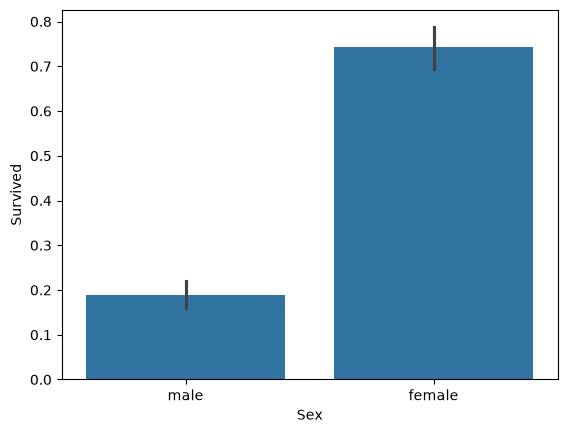

In [72]:
sns.barplot(data=train, y='Survived', x='Sex')
plt.ylabel('Survived'), 
plt.xlabel('Sex'), 
plt.title('Survival Based on Gender')
plt.savefig(RESULTS_DIR / "survival_by_gender.png")
plt.show()

In [37]:
#Survival based on passenger class
print(train.groupby('Pclass')['Survived'].mean())

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


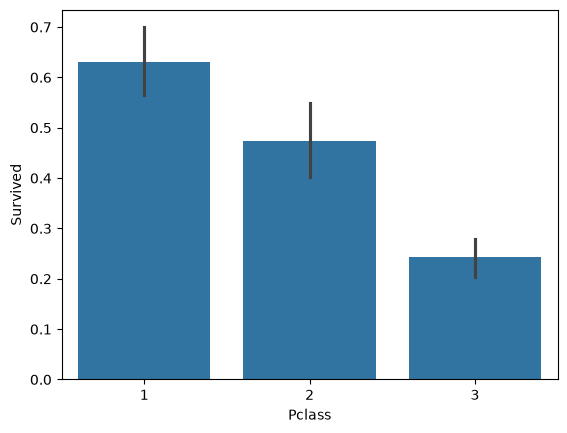

In [73]:
sns.barplot(data=train, y='Survived', x='Pclass')
plt.ylabel('Survived')
plt.xlabel=('Pclass')
plt.title=('Survival Based on Passenger Class')
plt.savefig(RESULTS_DIR / "survival_by_Passenger_Class.png")
plt.show()

In [57]:
# Survival by exact age (exploratory)
print(train.groupby('Age')['Survived'].mean())

Age
0.42     1.0
0.67     1.0
0.75     1.0
0.83     1.0
0.92     1.0
        ... 
70.00    0.0
70.50    0.0
71.00    0.0
74.00    0.0
80.00    1.0
Name: Survived, Length: 88, dtype: float64


In [61]:
# Survival based on AgeGroup
train['AgeGroup']= pd.cut(train['Age'], bins=[0, 12, 18, 35, 60, 80],
                           labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior'])

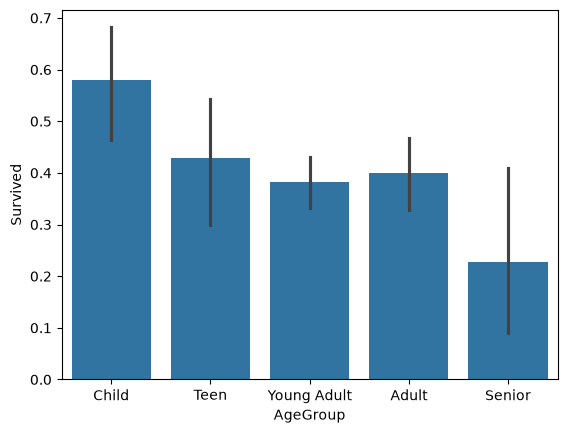

In [74]:
sns.barplot(data=train, y='Survived', x='AgeGroup')
plt.ylabel('Survived')
plt.xlabel('AgeGroup')
plt.title('Survival Based on Agegroup')
plt.savefig(RESULTS_DIR / "survival_by_Age_Group.png")
plt.show()